In [9]:
import numpy as np
import RandomTilings as RT
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [3]:
# Minimal hexagon rasterizer for the edge matrix used by _draw_lozenges.py.
# Fixed masks from the supplied drawing: no fac, Numba, or parallelization.
# Labels: 0 = background, 1 = left, 2 = right, 3 = horizontal lozenge.
# A, B, C are the integer side lengths used by the original library.
# For equal sides, call hexagon_image(M, n).
import numpy as np
from operator import index


# Rows run from top to bottom. Each 1 is ONE square output pixel.
LEFT = np.array([
    [0, 0, 0, 0],
    [0, 0, 1, 1],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [1, 1, 0, 0],
], dtype=bool)

RIGHT = np.array([
    [0, 0, 0, 0],
    [1, 1, 0, 0],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [0, 0, 1, 1],
], dtype=bool)

HORIZONTAL = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 1, 0, 0],
    [1, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 1, 1, 1, 1, 0, 0],
], dtype=bool)


def hexagon_image(M, A, B=None, C=None):
    # Return an int8 image. Omitting B and C means an equal-sided hexagon.
    # Input must be a valid tiling; exterior padding edges are ignored.
    A = index(A)
    B = A if B is None else index(B)
    C = A if C is None else index(C)
    if min(A, B, C) < 1:
        raise ValueError('A, B and C must be positive integer side lengths')
    N = 2*(A+B+C-1)
    M = np.asarray(M)
    if M.shape != (N, N):
        raise ValueError(f'M must have shape {(N, N)} for these side lengths')
    if M.dtype.kind not in 'biu':
        raise TypeError('M must contain integers or booleans')

    image = np.zeros((2*(2*A+B+C), 4*(B+C)), dtype=np.int8)
    top = 2*A+C
    for row, col in zip(*np.nonzero(M == 1)):
        # The library uses 1-based x,y with y increasing upward.
        x, y = int(col)+1, N-int(row)

        # Same domain test as in_hexagon() in the original source.
        # The sampler also stores active edges OUTSIDE this domain.
        if not 1 <= x <= 2*(B+C)-1:
            continue
        low = max(1, x-2*B+1)
        high = 2*A+min(x, 2*C)-1
        if not low <= y <= high:
            continue

        if x % 2:  # The two side lozenges.
            mask, color = (LEFT, 1) if y % 2 == 0 else (RIGHT, 2)
            r0 = 2*(top-y+(x-1)//2-1)
            c0 = 2*(x-1)
        else:      # The horizontal lozenge.
            mask, color = HORIZONTAL, 3
            r0 = 2*(top-y+x//2-1)
            c0 = 2*(x-2)

        # Stamp only the True entries; False entries leave neighbors intact.
        height, width = mask.shape
        patch = image[r0:r0+height, c0:c0+width]
        patch[mask] = color
    return image

In [19]:
n = 1000
H = RT.Hexagon(n)
H.shuffle()
M = H.get_edge_matrix()

Numerical instability detected: Overflow/Underflow!


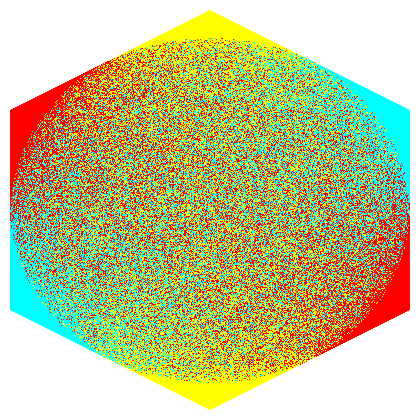

In [20]:
image = hexagon_image(M,n)
cmap = np.array([[1,1,1],
                 [1.0,0.0,0.0],
                 [0.0,1.0,1.0],
                 [1.0,1.0,0.0]])
cmap = ListedColormap(cmap)
fig = plt.figure(figsize=(4, 4), dpi=100, layout='none')
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(
    image,
    origin='upper',
    interpolation='nearest',
    cmap=cmap,
    vmin=-0.5,
    vmax=3.5,
)
ax.set_axis_off()

In [23]:
filename = 'hexa_pixel.png'
plt.imsave(filename, image, cmap=cmap,
                   origin='upper',
                       vmin=-0.5,
                       vmax=3.5, dpi=image.shape[1]/4)